In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()

# If Jupyter was launched from another directory, locate the repository.
if not (ROOT / "outputs").exists():
    ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

FEATURES_PATH = ROOT / "outputs/dsa/football2_unified_player_features.csv"
TRACKS_PATH = ROOT / "outputs/joint_tracking/football2_player_tracks.csv"

features = pd.read_csv(FEATURES_PATH)
tracks = pd.read_csv(TRACKS_PATH)

print("Project:", ROOT)
print("Unified features:", features.shape)
print("Frame-level tracks:", tracks.shape)
print("Unique track IDs:", tracks["canonical_id"].nunique())

Project: /mnt/d/My Projects/AthletiQ/AthletiQ
Unified features: (76, 47)
Frame-level tracks: (8569, 13)
Unique track IDs: 76


In [2]:
tracks["canonical_id"] = tracks["canonical_id"].astype(str)

track_quality = tracks.groupby("canonical_id").agg(
    observed_frames=("frame_id", "nunique"),
    first_time=("time_seconds", "min"),
    last_time=("time_seconds", "max"),
    mean_detection_confidence=("confidence", "mean"),
    min_detection_confidence=("confidence", "min"),
)

track_quality["duration_seconds"] = (
    track_quality["last_time"] - track_quality["first_time"]
)

track_quality["duration_seconds"].describe()

count    76.000000
mean      4.686842
std       4.362641
min       0.000000
25%       0.800000
50%       3.420000
75%       7.190000
max      16.360000
Name: duration_seconds, dtype: float64

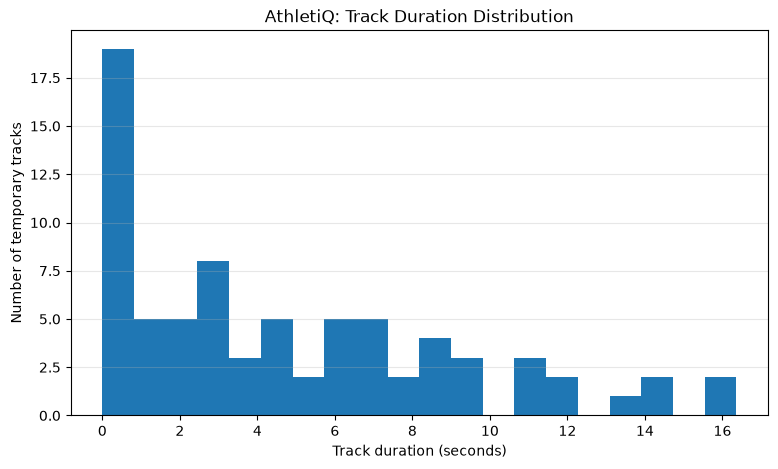

In [3]:
plt.figure(figsize=(9, 5))
plt.hist(track_quality["duration_seconds"], bins=20)
plt.xlabel("Track duration (seconds)")
plt.ylabel("Number of temporary tracks")
plt.title("AthletiQ: Track Duration Distribution")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [5]:

# Rebuild track-quality summary from raw tracking data
tracks["canonical_id"] = tracks["canonical_id"].astype(str)

track_quality = (
    tracks.groupby("canonical_id")
    .agg(
        observed_frames=("frame_id", "nunique"),
        first_time=("time_seconds", "min"),
        last_time=("time_seconds", "max"),
        mean_detection_confidence=("confidence", "mean"),
        min_detection_confidence=("confidence", "min"),
        mean_identity_confidence=("identity_confidence", "mean"),
    )
)

track_quality["duration_seconds"] = (
    track_quality["last_time"] - track_quality["first_time"]
)

track_quality["review_flag"] = "review_not_triggered"

track_quality.loc[
    track_quality["duration_seconds"] < 1,
    "review_flag"
] = "short_track"

track_quality.loc[
    track_quality["mean_detection_confidence"] < 0.5,
    "review_flag"
] = "low_detection_confidence"

display(
    track_quality.sort_values(
        ["duration_seconds", "mean_detection_confidence"]
    ).head(20).round(3)
)


,observed_frames,first_time,last_time,mean_detection_confidence,min_detection_confidence,mean_identity_confidence,duration_seconds,review_flag
canonical_id,,,,,,,,
48,1,17.84,17.84,0.489,0.489,1.0,0.00,low_detection_confidence
62,1,21.60,21.60,0.546,0.546,1.0,0.00,short_track
59,1,20.64,20.64,0.552,0.552,1.0,0.00,short_track
25,1,4.72,4.72,0.563,0.563,1.0,0.00,short_track
70,1,24.12,24.12,0.680,0.680,1.0,0.00,short_track
18,1,1.76,1.76,0.711,0.711,1.0,0.00,short_track
68,1,23.96,23.96,0.842,0.842,1.0,0.00,short_track
61,2,21.60,21.64,0.542,0.409,1.0,0.04,short_track
15,2,1.08,1.12,0.574,0.391,1.0,0.04,short_track


In [6]:
# Inspect raw observations for track 48
track_id = "48"

print("Raw tracking columns:")
print(tracks.columns.tolist())

print("\nRaw rows for track 48:")
display(
    tracks.loc[
        tracks["canonical_id"].astype(str) == track_id,
        [
            "canonical_id",
            "frame_id",
            "time_seconds",
            "confidence",
            "identity_confidence",
        ],
    ].head(10)
)

print("\nColumn data types:")
display(tracks[[
    "frame_id",
    "time_seconds",
    "confidence",
    "identity_confidence",
]].dtypes)

print("\nDirect aggregation:")
display(
    tracks.assign(
        canonical_id=tracks["canonical_id"].astype(str)
    )
    .query("canonical_id == @track_id")
    .agg({
        "frame_id": "nunique",
        "time_seconds": ["min", "max"],
        "confidence": ["mean", "min"],
        "identity_confidence": "mean",
    })
)

Raw tracking columns:
['frame_id', 'time_seconds', 'canonical_id', 'mixsort_id', 'x1', 'y1', 'x2', 'y2', 'center_x', 'center_y', 'confidence', 'stitched', 'identity_confidence']

Raw rows for track 48:


,canonical_id,frame_id,time_seconds,confidence,identity_confidence
4993,48,446,17.84,0.489341,1.0



Column data types:


frame_id                 int64
time_seconds           float64
confidence             float64
identity_confidence    float64
dtype: object


Direct aggregation:


,frame_id,time_seconds,confidence,identity_confidence
nunique,1.0,NaN,NaN,NaN
min,NaN,17.84,0.489341,NaN
max,NaN,17.84,NaN,NaN
mean,NaN,NaN,0.489341,1.0


In [7]:
# Track-quality categories based on actual frame observations

quality = tracks.groupby("canonical_id").agg(
    observed_frames=("frame_id", "nunique"),
    first_time=("time_seconds", "min"),
    last_time=("time_seconds", "max"),
    mean_detection_confidence=("confidence", "mean"),
)

quality["duration_seconds"] = (
    quality["last_time"] - quality["first_time"]
)

quality["quality_category"] = np.select(
    [
        quality["observed_frames"] < 3,
        quality["observed_frames"] < 10,
        quality["observed_frames"] < 25,
    ],
    [
        "single_or_two_frame_detection",
        "very_short_track",
        "short_track",
    ],
    default="longer_track",
)

print("Track counts by category:")
display(
    quality["quality_category"]
    .value_counts()
    .rename_axis("category")
    .to_frame("track_count")
)

print("\nTrack-quality summary:")
display(
    quality.groupby("quality_category", observed=True)
    .agg(
        track_count=("observed_frames", "size"),
        median_frames=("observed_frames", "median"),
        median_duration=("duration_seconds", "median"),
        mean_detection_confidence=("mean_detection_confidence", "mean"),
    )
    .round(3)
)

Track counts by category:


,track_count
category,
longer_track,52
single_or_two_frame_detection,11
short_track,7
very_short_track,6



Track-quality summary:


,track_count,median_frames,median_duration,mean_detection_confidence
quality_category,,,,
longer_track,52,145.0,5.92,0.860
short_track,7,16.0,0.92,0.668
single_or_two_frame_detection,11,1.0,0.00,0.618
very_short_track,6,4.0,0.18,0.506


In [8]:

import numpy as np
import pandas as pd
from itertools import combinations

# Use frame-level tracking observations
required = {
    "canonical_id", "frame_id", "time_seconds",
    "center_x", "center_y", "confidence",
}
assert required.issubset(tracks.columns), (
    f"Missing columns: {required - set(tracks.columns)}"
)

track_summary = (
    tracks.groupby("canonical_id")
    .agg(
        first_frame=("frame_id", "min"),
        last_frame=("frame_id", "max"),
        first_time=("time_seconds", "min"),
        last_time=("time_seconds", "max"),
        first_x=("center_x", "first"),
        first_y=("center_y", "first"),
        last_x=("center_x", "last"),
        last_y=("center_y", "last"),
        mean_confidence=("confidence", "mean"),
        observed_frames=("frame_id", "nunique"),
    )
)

# Get the true first and last observation coordinates in frame order.
ordered = tracks.sort_values(["canonical_id", "frame_id"])
first_obs = ordered.groupby("canonical_id").first()
last_obs = ordered.groupby("canonical_id").last()

track_summary["first_x"] = first_obs["center_x"]
track_summary["first_y"] = first_obs["center_y"]
track_summary["last_x"] = last_obs["center_x"]
track_summary["last_y"] = last_obs["center_y"]

pairs = []

MAX_GAP_FRAMES = 75       # 3 seconds at 25 FPS
MAX_DISTANCE_PX = 100     # permissive candidate filter, not a merge rule

for a, b in combinations(track_summary.index, 2):
    A = track_summary.loc[a]
    B = track_summary.loc[b]

    # Order tracks chronologically: A must end before B begins.
    if A["last_frame"] > B["first_frame"]:
        if B["last_frame"] <= A["first_frame"]:
            A, B = B, A
            a, b = b, a
        else:
            continue  # temporal overlap: needs a separate review

    gap = B["first_frame"] - A["last_frame"]
    if gap < 1 or gap > MAX_GAP_FRAMES:
        continue

    distance = np.hypot(
        B["first_x"] - A["last_x"],
        B["first_y"] - A["last_y"],
    )

    if distance > MAX_DISTANCE_PX:
        continue

    pairs.append({
        "track_a": a,
        "track_b": b,
        "gap_frames": int(gap),
        "gap_seconds": round(gap / 25, 2),
        "endpoint_distance_px": round(float(distance), 2),
        "track_a_frames": int(A["observed_frames"]),
        "track_b_frames": int(B["observed_frames"]),
        "track_a_confidence": round(float(A["mean_confidence"]), 3),
        "track_b_confidence": round(float(B["mean_confidence"]), 3),
    })

candidate_pairs = pd.DataFrame(pairs)

if candidate_pairs.empty:
    print("No candidate pairs passed the initial filter.")
else:
    candidate_pairs = candidate_pairs.sort_values(
        ["gap_frames", "endpoint_distance_px"]
    ).reset_index(drop=True)

    display(candidate_pairs.head(30))
    print("Candidate pairs:", len(candidate_pairs))


,track_a,track_b,gap_frames,gap_seconds,endpoint_distance_px,track_a_frames,track_b_frames,track_a_confidence,track_b_confidence
0,59,60,1,0.04,54.21,1,139,0.552,0.796
1,46,71,2,0.08,93.32,196,90,0.875,0.903
2,14,18,4,0.16,93.68,23,1,0.597,0.711
3,44,57,5,0.20,57.16,107,24,0.790,0.619
4,61,63,5,0.20,88.18,2,2,0.542,0.610
5,15,16,6,0.24,14.67,2,3,0.574,0.435
6,62,63,6,0.24,87.67,1,2,0.546,0.610
7,42,49,7,0.28,3.69,83,155,0.914,0.851
8,39,47,8,0.32,11.25,81,240,0.878,0.728
9,16,18,8,0.32,32.63,3,1,0.435,0.711


Candidate pairs: 95


In [9]:

# Rank candidate pairs for manual identity review.
# This does not merge any tracks.

review = candidate_pairs.copy()

# Recalculate from the actual columns; do not trust the displayed row index.
review["min_track_frames"] = review[
    ["track_a_frames", "track_b_frames"]
].min(axis=1)

review["max_track_frames"] = review[
    ["track_a_frames", "track_b_frames"]
].max(axis=1)

# Normalize simple evidence terms to [0, 1].
# Lower endpoint distance and gap are preferable.
distance_score = 1 - (
    review["endpoint_distance_px"] / 100
).clip(0, 1)

gap_score = 1 - (
    review["gap_frames"] / 75
).clip(0, 1)

# Longer trajectories offer more evidence for motion/appearance review.
duration_evidence = (
    np.log1p(review["min_track_frames"])
    / np.log1p(review["min_track_frames"].max())
).clip(0, 1)

review["review_priority"] = (
    0.40 * distance_score
    + 0.25 * gap_score
    + 0.35 * duration_evidence
).round(3)

review = review.sort_values(
    ["review_priority", "endpoint_distance_px"],
    ascending=[False, True],
).reset_index(drop=True)

display(
    review[
        [
            "track_a",
            "track_b",
            "gap_frames",
            "endpoint_distance_px",
            "track_a_frames",
            "track_b_frames",
            "review_priority",
        ]
    ].head(25)
)


,track_a,track_b,gap_frames,endpoint_distance_px,track_a_frames,track_b_frames,review_priority
0,42,49,7,3.69,83,155,0.895
1,39,47,8,11.25,81,240,0.860
2,44,60,16,15.65,107,139,0.834
3,11,28,46,7.59,215,108,0.766
4,40,75,16,14.64,309,24,0.744
5,4,30,51,22.49,237,266,0.740
6,4,28,24,34.64,237,108,0.731
7,35,65,33,36.29,223,145,0.714
8,36,44,12,47.89,71,107,0.692
9,72,75,24,22.35,38,24,0.686


In [11]:

# Inspect exact observations around the proposed transition.
track_a, track_b = 42, 49

a = tracks[tracks["canonical_id"].astype(str) == str(track_a)].sort_values("frame_id")
b = tracks[tracks["canonical_id"].astype(str) == str(track_b)].sort_values("frame_id")

print("TRACK A — final observations")
display(a.tail(5)[[
    "frame_id", "time_seconds", "x1", "y1", "x2", "y2",
    "center_x", "center_y", "confidence"
]])

print("TRACK B — first observations")
display(b.head(5)[[
    "frame_id", "time_seconds", "x1", "y1", "x2", "y2",
    "center_x", "center_y", "confidence"
]])

print("Last frame A:", a["frame_id"].max())
print("First frame B:", b["frame_id"].min())
print("Gap:", b["frame_id"].min() - a["frame_id"].max(), "frames")


TRACK A — final observations


,frame_id,time_seconds,x1,y1,x2,y2,center_x,center_y,confidence
4919,440,17.60,755.553,237.129,773.906,275.302,764.730,256.216,0.899807
4931,441,17.64,758.113,240.729,774.069,276.389,766.091,258.559,0.745818
4943,442,17.68,760.234,242.782,773.424,274.500,766.829,258.641,0.560282
4955,443,17.72,760.640,240.831,773.692,274.815,767.166,257.823,0.490218
4967,444,17.76,760.530,239.280,773.611,275.985,767.071,257.632,0.628610


TRACK B — first observations


,frame_id,time_seconds,x1,y1,x2,y2,center_x,center_y,confidence
5046,451,18.04,764.120,234.005,768.247,274.091,766.184,254.048,0.652556
5056,452,18.08,763.852,234.744,767.840,273.273,765.846,254.008,0.842787
5068,453,18.12,762.840,235.542,766.779,272.430,764.809,253.986,0.851516
5080,454,18.16,761.706,235.063,765.926,272.609,763.816,253.836,0.917190
5092,455,18.20,760.740,234.988,765.227,272.059,762.983,253.523,0.924287


Last frame A: 444
First frame B: 451
Gap: 7 frames


Track 42 ends at frame 444; track 49 begins at frame 451.


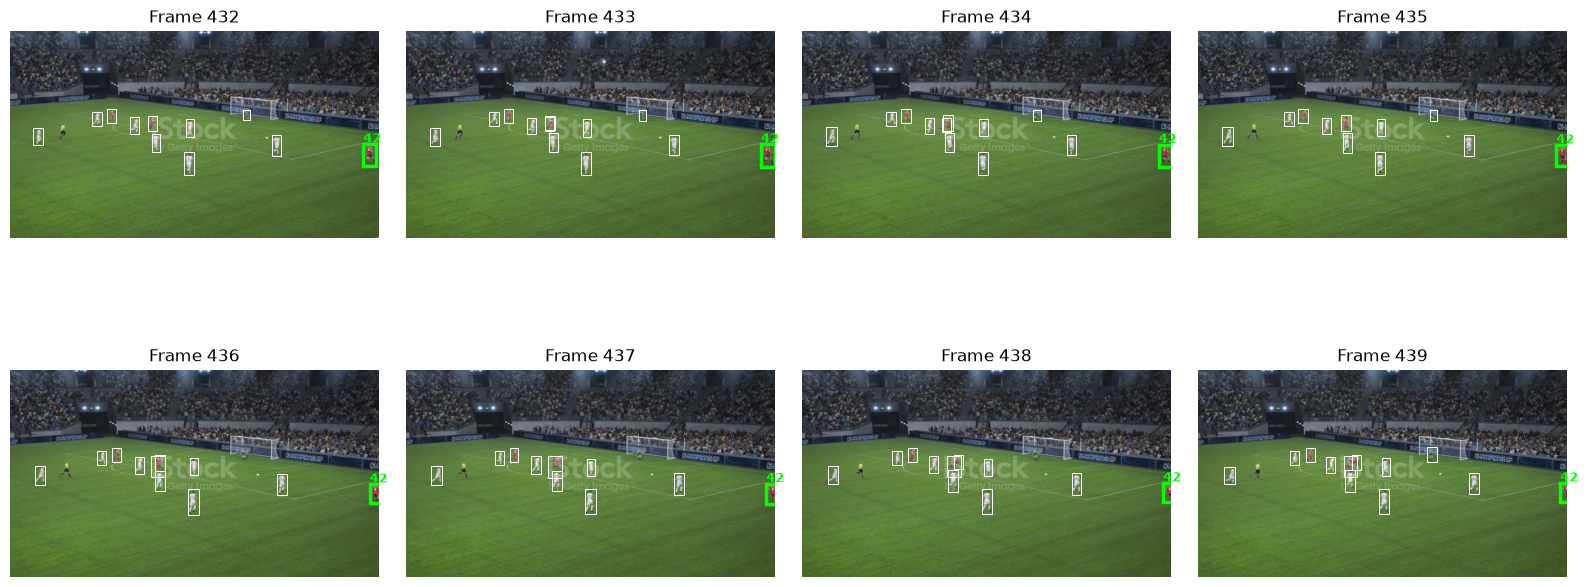

In [12]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

VIDEO_PATH = ROOT / "datasets/football/raw/videos/football2.mp4"

def inspect_track_transition(track_a, track_b, padding_frames=8):
    a = tracks[tracks["canonical_id"].astype(str) == str(track_a)]
    b = tracks[tracks["canonical_id"].astype(str) == str(track_b)]

    if a.empty or b.empty:
        print("One or both track IDs were not found.")
        return

    a_end = int(a["frame_id"].max())
    b_start = int(b["frame_id"].min())

    print(
        f"Track {track_a} ends at frame {a_end}; "
        f"track {track_b} begins at frame {b_start}."
    )

    cap = cv2.VideoCapture(str(VIDEO_PATH))
    if not cap.isOpened():
        print("Could not open video:", VIDEO_PATH)
        return

    frame_ids = sorted(set(
        list(range(max(0, a_end - padding_frames), a_end + 1))
        + list(range(b_start, b_start + padding_frames + 1))
    ))

    fig, axes = plt.subplots(
        2, 4, figsize=(16, 8)
    )
    axes = axes.flatten()

    for ax, frame_id in zip(axes, frame_ids[:8]):
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
        ok, frame = cap.read()

        if not ok:
            ax.set_title(f"Frame {frame_id}: unavailable")
            ax.axis("off")
            continue

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame_rows = tracks[tracks["frame_id"] == frame_id]

        ax.imshow(frame)

        for _, row in frame_rows.iterrows():
            x1, y1, x2, y2 = (
                row["x1"], row["y1"], row["x2"], row["y2"]
            )
            cid = str(row["canonical_id"])

            if cid in {str(track_a), str(track_b)}:
                color = "lime"
                linewidth = 2.5
            else:
                color = "white"
                linewidth = 0.7

            rect = plt.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor=color, linewidth=linewidth
            )
            ax.add_patch(rect)

            if cid in {str(track_a), str(track_b)}:
                ax.text(x1, max(0, y1 - 4), cid, color=color,
                        fontsize=9, weight="bold")

        ax.set_title(f"Frame {frame_id}")
        ax.axis("off")

    for ax in axes[min(len(frame_ids), 8):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    cap.release()

inspect_track_transition(42, 49, padding_frames=12)


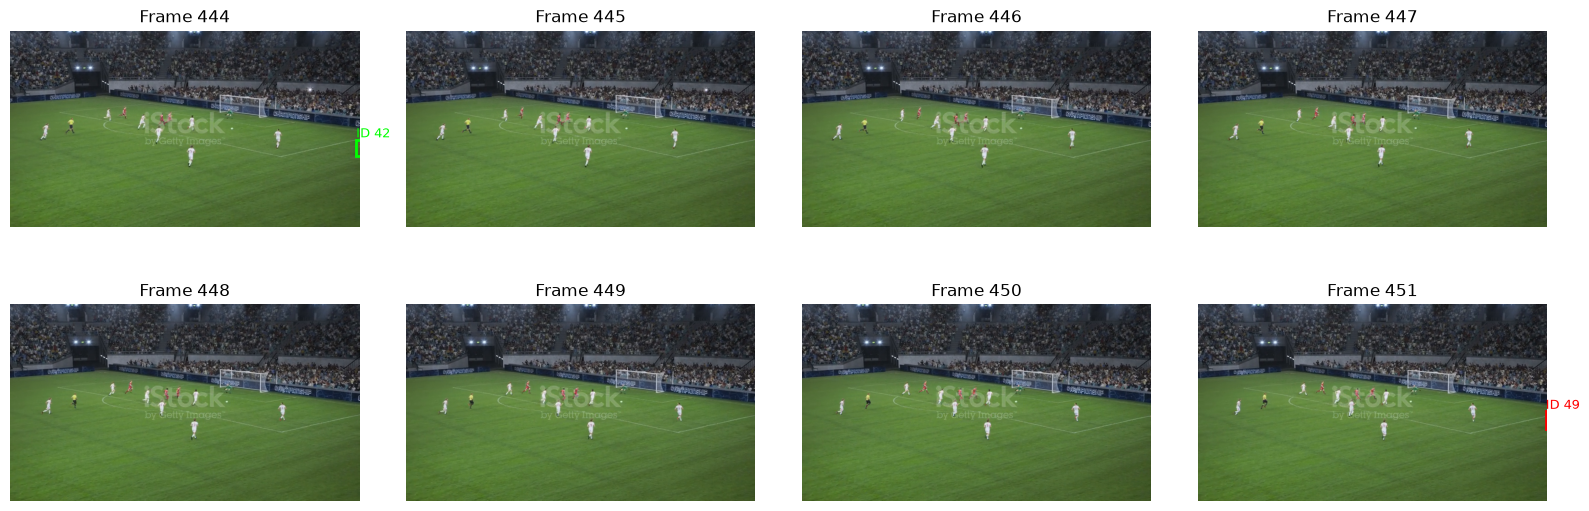

In [13]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

video_path = ROOT / "datasets/football/raw/videos/football2.mp4"
cap = cv2.VideoCapture(str(video_path))

fig, axes = plt.subplots(2, 4, figsize=(16, 6))

for ax, frame_id in zip(axes.flat, range(444, 452)):
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ok, frame = cap.read()

    if not ok:
        ax.set_title(f"Frame {frame_id}: unavailable")
        ax.axis("off")
        continue

    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    rows = tracks[tracks["frame_id"] == frame_id]

    for _, r in rows.iterrows():
        tid = str(r["canonical_id"])
        if tid not in {"42", "49"}:
            continue

        x1, y1, x2, y2 = [
            int(r[c]) for c in ["x1", "y1", "x2", "y2"]
        ]
        color = "lime" if tid == "42" else "red"
        ax.add_patch(plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor=color, linewidth=2
        ))
        ax.text(x1, max(12, y1 - 5), f"ID {tid}",
                color=color, fontsize=9)

    ax.imshow(frame)
    ax.set_title(f"Frame {frame_id}")
    ax.axis("off")

cap.release()
plt.tight_layout()
plt.show()


In [15]:

# Normalize IDs to integers before applying the mapping
tracks_stitched = tracks.copy()

tracks_stitched["canonical_id"] = (
    tracks_stitched["canonical_id"].astype(int)
)

stitch_map = {49: 42}

tracks_stitched["canonical_id"] = (
    tracks_stitched["canonical_id"].replace(stitch_map)
)

print("Original unique IDs:", tracks["canonical_id"].nunique())
print("Stitched unique IDs:", tracks_stitched["canonical_id"].nunique())
print("Rows preserved:", len(tracks_stitched) == len(tracks))

# Verify the two track fragments now share ID 42
display(
    tracks_stitched[
        tracks_stitched["frame_id"].between(440, 455)
        & tracks_stitched["canonical_id"].eq(42)
    ][["frame_id", "canonical_id", "center_x", "center_y", "confidence"]]
    .sort_values("frame_id")
)


Original unique IDs: 76
Stitched unique IDs: 75
Rows preserved: True


,frame_id,canonical_id,center_x,center_y,confidence
4919,440,42,764.730,256.216,0.899807
4931,441,42,766.091,258.559,0.745818
4943,442,42,766.829,258.641,0.560282
4955,443,42,767.166,257.823,0.490218
4967,444,42,767.071,257.632,0.628610
5046,451,42,766.184,254.048,0.652556
5056,452,42,765.846,254.008,0.842787
5068,453,42,764.809,253.986,0.851516
5080,454,42,763.816,253.836,0.917190
5092,455,42,762.983,253.523,0.924287


Track 39 ends at frame 402; track 47 begins at frame 410.


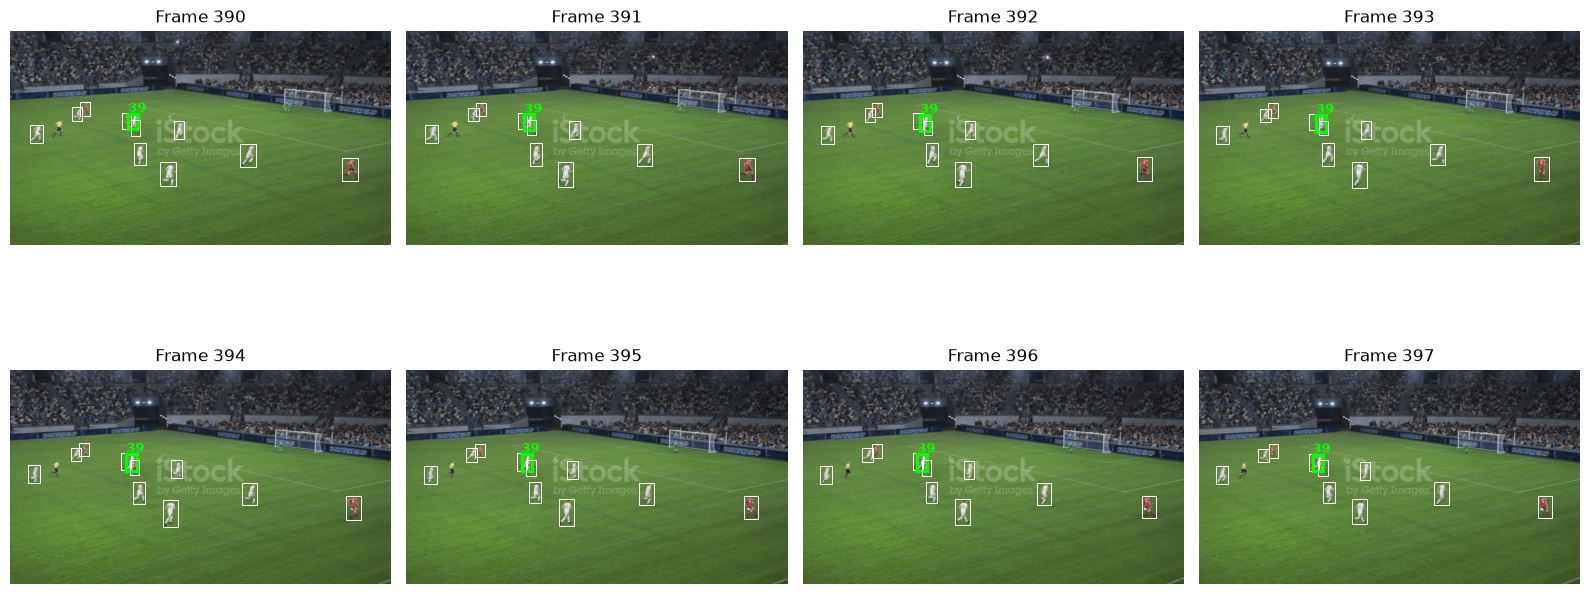

In [16]:

inspect_track_transition(39, 47, padding_frames=12)


In [17]:

track_a, track_b = 39, 47

a = tracks[tracks["canonical_id"].astype(str) == str(track_a)].sort_values("frame_id")
b = tracks[tracks["canonical_id"].astype(str) == str(track_b)].sort_values("frame_id")

print("TRACK 39 — final observations")
display(a.tail(5)[[
    "frame_id", "center_x", "center_y", "confidence"
]])

print("TRACK 47 — first observations")
display(b.head(5)[[
    "frame_id", "center_x", "center_y", "confidence"
]])


TRACK 39 — final observations


,frame_id,center_x,center_y,confidence
4426,398,238.027,189.322,0.848411
4437,399,237.832,189.628,0.787674
4448,400,236.943,190.043,0.862102
4459,401,238.585,190.577,0.769233
4471,402,238.046,190.789,0.848442


TRACK 47 — first observations


,frame_id,center_x,center_y,confidence
4569,410,248.634,186.987,0.600777
4581,411,249.405,186.559,0.581343
4594,412,252.275,187.142,0.771442
4605,413,253.683,187.539,0.776119
4616,414,254.686,187.969,0.818509


In [18]:

import numpy as np
import pandas as pd
from pathlib import Path

# Uses your existing ROOT and original tracks DataFrame.
OUT = ROOT / "outputs" / "joint_tracking"
OUT.mkdir(parents=True, exist_ok=True)

df = tracks.copy()
df["canonical_id"] = pd.to_numeric(df["canonical_id"]).astype(int)
df["frame_id"] = pd.to_numeric(df["frame_id"]).astype(int)

# One summary row per original track.
summaries = []

for tid, g in df.groupby("canonical_id"):
    g = g.sort_values("frame_id")
    first, last = g.iloc[0], g.iloc[-1]
    summaries.append({
        "track_id": int(tid),
        "first_frame": int(first.frame_id),
        "last_frame": int(last.frame_id),
        "n_frames": int(g.frame_id.nunique()),
        "start_x": float(first.center_x),
        "start_y": float(first.center_y),
        "end_x": float(last.center_x),
        "end_y": float(last.center_y),
        "start_w": float(first.x2 - first.x1),
        "start_h": float(first.y2 - first.y1),
        "end_w": float(last.x2 - last.x1),
        "end_h": float(last.y2 - last.y1),
    })

s = pd.DataFrame(summaries).set_index("track_id").sort_values("first_frame")

# Estimate endpoint velocity from the final / initial observations.
velocity = {}
for tid, g in df.groupby("canonical_id"):
    g = g.sort_values("frame_id")
    if len(g) >= 2:
        tail = g.tail(min(5, len(g)))
        head = g.head(min(5, len(g)))
        dt_tail = tail.frame_id.iloc[-1] - tail.frame_id.iloc[0]
        dt_head = head.frame_id.iloc[-1] - head.frame_id.iloc[0]
        vx_end = (tail.center_x.iloc[-1] - tail.center_x.iloc[0]) / max(dt_tail, 1)
        vy_end = (tail.center_y.iloc[-1] - tail.center_y.iloc[0]) / max(dt_tail, 1)
        vx_start = (head.center_x.iloc[-1] - head.center_x.iloc[0]) / max(dt_head, 1)
        vy_start = (head.center_y.iloc[-1] - head.center_y.iloc[0]) / max(dt_head, 1)
    else:
        vx_end = vy_end = vx_start = vy_start = 0.0
    velocity[int(tid)] = (vx_start, vy_start, vx_end, vy_end)

MAX_GAP = 75
MAX_DISTANCE = 100
candidates = []

for a_id, a in s.iterrows():
    for b_id, b in s.iterrows():
        gap = int(b.first_frame - a.last_frame)
        if a_id == b_id or gap < 1 or gap > MAX_GAP:
            continue

        # Predict A's position at B's start, capped to avoid long extrapolations.
        _, _, avx, avy = velocity[int(a_id)]
        bvx, bvy, _, _ = velocity[int(b_id)]
        dt = min(gap, 15)
        pred_x = a.end_x + avx * dt
        pred_y = a.end_y + avy * dt
        pred_dist = float(np.hypot(b.start_x - pred_x, b.start_y - pred_y))
        raw_dist = float(np.hypot(b.start_x - a.end_x, b.start_y - a.end_y))

        # Relative box-size change (robust to near-zero dimensions).
        wa, ha = max(a.end_w, 1), max(a.end_h, 1)
        wb, hb = max(b.start_w, 1), max(b.start_h, 1)
        size_change = abs(np.log(wb / wa)) + abs(np.log(hb / ha))

        # Strict filters: short temporal gap, plausible motion, similar box geometry.
        if raw_dist > MAX_DISTANCE or pred_dist > MAX_DISTANCE or size_change > 1.5:
            continue

        # Score ranks candidates; it is a heuristic, not a calibrated probability.
        score = (
            0.40 * np.exp(-pred_dist / 35)
            + 0.25 * np.exp(-raw_dist / 45)
            + 0.20 * np.exp(-gap / 25)
            + 0.15 * np.exp(-size_change)
        )

        candidates.append({
            "track_a": int(a_id),
            "track_b": int(b_id),
            "gap_frames": gap,
            "raw_distance_px": raw_dist,
            "predicted_distance_px": pred_dist,
            "box_size_change": size_change,
            "score": float(score),
        })

cand = pd.DataFrame(candidates)
if cand.empty:
    raise RuntimeError("No candidates found; inspect the tracking data and thresholds.")

cand = cand.sort_values("score", ascending=False).reset_index(drop=True)

# Conservative automatic merge:
# require strong score and mutual-best preference at both ends.
best_out = cand.groupby("track_a")["score"].max().to_dict()
best_in = cand.groupby("track_b")["score"].max().to_dict()

cand["mutual_best"] = cand.apply(
    lambda r: (
        r.score >= 0.82
        and r.score >= best_out[r.track_a] - 1e-9
        and r.score >= best_in[r.track_b] - 1e-9
    ),
    axis=1
)

# Prevent any track from having multiple predecessors or successors.
accepted = []
used_out, used_in = set(), set()

for r in cand[cand["mutual_best"]].sort_values("score", ascending=False).itertuples():
    if r.track_a in used_out or r.track_b in used_in:
        continue
    accepted.append({
        "track_a": r.track_a,
        "track_b": r.track_b,
        "gap_frames": r.gap_frames,
        "raw_distance_px": r.raw_distance_px,
        "predicted_distance_px": r.predicted_distance_px,
        "box_size_change": r.box_size_change,
        "score": r.score,
        "decision": "auto_merge",
    })
    used_out.add(r.track_a)
    used_in.add(r.track_b)

accepted_df = pd.DataFrame(accepted)

# Build a directed mapping and resolve chains to the earliest track ID.
parent = {int(t): int(t) for t in s.index}
next_track = {
    int(r.track_a): int(r.track_b)
    for r in accepted_df.itertuples()
}

def resolve(tid):
    seen = set()
    cur = int(tid)
    while cur in next_track:
        if cur in seen:
            raise RuntimeError("Cycle detected in identity mapping")
        seen.add(cur)
        cur = next_track[cur]
    return cur

# The earliest-starting fragment is used as canonical ID for each chain.
for a_id, b_id in next_track.items():
    if s.loc[a_id, "first_frame"] > s.loc[b_id, "first_frame"]:
        raise RuntimeError(f"Non-forward temporal edge detected: {a_id}->{b_id}")

mapping = {int(t): resolve(int(t)) for t in s.index}

# Save outputs without overwriting the original tracking CSV.
df["original_track_id"] = df["canonical_id"]
df["canonical_id"] = df["original_track_id"].map(mapping)

df.to_csv(OUT / "football2_player_tracks_stitched.csv", index=False)
cand.to_csv(OUT / "football2_stitch_candidates.csv", index=False)
accepted_df.to_csv(OUT / "football2_stitch_accepted.csv", index=False)
pd.DataFrame([
    {"original_track_id": k, "canonical_id": v}
    for k, v in mapping.items()
]).to_csv(OUT / "football2_stitch_mapping.csv", index=False)

print("Original track IDs:", s.shape[0])
print("Automatically accepted links:", len(accepted_df))
print("Resulting canonical IDs:", df["canonical_id"].nunique())
print("Rows preserved:", len(df) == len(tracks))
print("\nAccepted links:")
display(accepted_df)
print("\nTop candidates for review:")
display(cand[~cand["mutual_best"]].head(20))
print("\nSaved outputs to:", OUT)


Original track IDs: 76
Automatically accepted links: 0
Resulting canonical IDs: 76
Rows preserved: True

Accepted links:


""



Top candidates for review:


,track_a,track_b,gap_frames,raw_distance_px,predicted_distance_px,box_size_change,score,mutual_best
0,15,16,6,14.665430,11.061749,0.108921,0.763925,False
1,42,49,7,3.692130,7.847650,1.241724,0.744453,False
2,39,47,8,11.249931,12.517036,0.301727,0.730594,False
3,63,65,11,24.594308,7.789596,0.104963,0.728785,False
4,35,63,19,7.195230,12.722852,0.403554,0.684876,False
5,52,54,16,29.948634,7.989444,0.315903,0.661693,False
6,62,69,60,6.823942,6.823942,1.051609,0.614517,False
7,40,76,34,31.103029,8.075300,0.705272,0.568258,False
8,16,18,8,32.629501,22.320413,0.664326,0.554889,False
9,40,75,16,14.640465,27.211733,0.756268,0.540266,False



Saved outputs to: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/joint_tracking


In [19]:

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

# -------------------------------------------------------
# CONFIGURATION
# -------------------------------------------------------
FPS = 25
WINDOW_FRAMES = 5 * FPS       # 5 seconds = 125 frames
TARGET_IDS = 22

OUT = ROOT / "outputs" / "joint_tracking"
OUT.mkdir(parents=True, exist_ok=True)

df = tracks.copy()
df["canonical_id"] = pd.to_numeric(df["canonical_id"]).astype(int)
df["frame_id"] = pd.to_numeric(df["frame_id"]).astype(int)

# -------------------------------------------------------
# 1. SUMMARIZE EACH TRACK USING UP TO 5 SECONDS
#    OF OBSERVATIONS AT ITS START AND END
# -------------------------------------------------------
summaries = {}

for tid, g in df.groupby("canonical_id"):
    g = g.sort_values("frame_id").drop_duplicates("frame_id")
    first_frame = int(g["frame_id"].min())
    last_frame = int(g["frame_id"].max())

    start = g[g["frame_id"] <= first_frame + WINDOW_FRAMES]
    end = g[g["frame_id"] >= last_frame - WINDOW_FRAMES]

    def robust_velocity(part):
        if len(part) < 2:
            return np.zeros(2)
        t = part["frame_id"].to_numpy(dtype=float)
        x = part["center_x"].to_numpy(dtype=float)
        y = part["center_y"].to_numpy(dtype=float)

        # Robust linear trend over the window.
        vx = np.polyfit(t - t[0], x, 1)[0]
        vy = np.polyfit(t - t[0], y, 1)[0]
        return np.array([vx, vy])

    summaries[int(tid)] = {
        "first": first_frame,
        "last": last_frame,
        "n": len(g),
        "start_xy": g.iloc[0][["center_x", "center_y"]].to_numpy(float),
        "end_xy": g.iloc[-1][["center_x", "center_y"]].to_numpy(float),
        "start_velocity": robust_velocity(start),
        "end_velocity": robust_velocity(end),
        "start_box": g.iloc[0][["x2", "y2"]].to_numpy(float)
                     - g.iloc[0][["x1", "y1"]].to_numpy(float),
        "end_box": g.iloc[-1][["x2", "y2"]].to_numpy(float)
                   - g.iloc[-1][["x1", "y1"]].to_numpy(float),
    }

ids = sorted(summaries)
n = len(ids)

if n < TARGET_IDS:
    raise ValueError(f"Only {n} tracks found; cannot create {TARGET_IDS} nonempty clusters.")

# -------------------------------------------------------
# 2. PAIRWISE IDENTITY COST
#    Lower cost = more plausible same-player fragments
# -------------------------------------------------------
D = np.zeros((n, n), dtype=float)

for i in range(n):
    A = summaries[ids[i]]

    for j in range(i + 1, n):
        B = summaries[ids[j]]

        # Order the pair chronologically.
        if A["last"] <= B["first"]:
            earlier, later = A, B
        elif B["last"] <= A["first"]:
            earlier, later = B, A
        else:
            # Overlapping tracks cannot ordinarily be the same player.
            # High penalty, but clustering may still merge them to reach 22.
            D[i, j] = D[j, i] = 500.0
            continue

        gap = max(0, later["first"] - earlier["last"])
        gap_seconds = gap / FPS

        # Predict earlier track's endpoint to the later track's start.
        predicted = (
            earlier["end_xy"]
            + earlier["end_velocity"] * gap
        )
        prediction_error = np.linalg.norm(predicted - later["start_xy"])

        # Raw endpoint distance and direction compatibility.
        raw_distance = np.linalg.norm(
            earlier["end_xy"] - later["start_xy"]
        )

        v1 = earlier["end_velocity"]
        v2 = later["start_velocity"]
        norm_product = np.linalg.norm(v1) * np.linalg.norm(v2)

        if norm_product > 1e-6:
            cosine = np.clip(np.dot(v1, v2) / norm_product, -1, 1)
            direction_cost = (1 - cosine) / 2
        else:
            direction_cost = 0.5

        # Compare bounding-box sizes using log ratios.
        box1 = np.maximum(earlier["end_box"], 1)
        box2 = np.maximum(later["start_box"], 1)
        box_cost = np.abs(np.log(box1 / box2)).mean()

        # Five-second horizon; long gaps receive a growing penalty.
        gap_cost = gap_seconds / 5.0

        # Combined cost in pixel/frame-based feature space.
        cost = (
            0.45 * prediction_error
            + 0.20 * raw_distance
            + 20.0 * direction_cost
            + 15.0 * box_cost
            + 25.0 * gap_cost
        )

        D[i, j] = D[j, i] = max(float(cost), 1e-6)

# -------------------------------------------------------
# 3. CLUSTER ALL TRACKS INTO EXACTLY 22 GROUPS
# -------------------------------------------------------
np.fill_diagonal(D, 0.0)
condensed = squareform(D, checks=True)

Z = linkage(condensed, method="average")
cluster_labels = fcluster(Z, t=TARGET_IDS, criterion="maxclust")

# maxclust can theoretically produce fewer groups if linkage heights tie.
# Fall back to cutting the hierarchy into exactly 22 leaves.
if len(np.unique(cluster_labels)) != TARGET_IDS:
    from sklearn.cluster import AgglomerativeClustering
    model = AgglomerativeClustering(
        n_clusters=TARGET_IDS,
        metric="precomputed",
        linkage="average"
    )
    cluster_labels = model.fit_predict(D) + 1

assert len(np.unique(cluster_labels)) == TARGET_IDS

# Assign stable canonical IDs based on the earliest original track
# within each cluster; the resulting IDs are numbered 1 through 22.
cluster_members = pd.DataFrame({
    "original_track_id": ids,
    "cluster": cluster_labels
})

cluster_order = (
    cluster_members.merge(
        pd.Series(
            {tid: summaries[tid]["first"] for tid in ids},
            name="first_frame"
        ),
        left_on="original_track_id",
        right_index=True
    )
    .groupby("cluster")["first_frame"]
    .min()
    .sort_values()
)

cluster_to_canonical = {
    cluster: canonical_id
    for canonical_id, cluster in enumerate(cluster_order.index, start=1)
}

cluster_members["canonical_id"] = (
    cluster_members["cluster"].map(cluster_to_canonical)
)

id_map = dict(zip(
    cluster_members["original_track_id"],
    cluster_members["canonical_id"]
))

# -------------------------------------------------------
# 4. APPLY MAPPING AND SAVE ALL AUDIT OUTPUTS
# -------------------------------------------------------
stitched = df.copy()
stitched["original_track_id"] = stitched["canonical_id"]
stitched["canonical_id"] = stitched["original_track_id"].map(id_map)

mapping_path = OUT / "football2_auto_stitch_mapping_22.csv"
tracks_path = OUT / "football2_player_tracks_stitched_22.csv"
audit_path = OUT / "football2_auto_stitch_cluster_audit.csv"

cluster_members.to_csv(mapping_path, index=False)
stitched.to_csv(tracks_path, index=False)

cluster_audit = (
    cluster_members.groupby("canonical_id")
    .agg(
        original_track_count=("original_track_id", "nunique"),
        original_track_ids=("original_track_id",
                            lambda x: ",".join(map(str, sorted(x))))
    )
    .reset_index()
)
cluster_audit.to_csv(audit_path, index=False)

print("Original IDs:", df["canonical_id"].nunique())
print("Final canonical IDs:", stitched["canonical_id"].nunique())
print("Rows preserved:", len(stitched) == len(df))
print("Mapping:", mapping_path)
print("Stitched tracks:", tracks_path)
print("Cluster audit:", audit_path)

display(cluster_audit)
display(cluster_members.sort_values(["canonical_id", "original_track_id"]))


Original IDs: 76
Final canonical IDs: 22
Rows preserved: True
Mapping: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/joint_tracking/football2_auto_stitch_mapping_22.csv
Stitched tracks: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/joint_tracking/football2_player_tracks_stitched_22.csv
Cluster audit: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/joint_tracking/football2_auto_stitch_cluster_audit.csv


,canonical_id,original_track_count,original_track_ids
0,1,1,1
1,2,2,"8,38"
2,3,10,"5,14,15,16,18,20,22,27,31,32"
3,4,4,"4,11,28,37"
4,5,7,"7,9,19,23,25,29,36"
5,6,2,"2,41"
6,7,2,"3,33"
7,8,1,6
8,9,1,12
9,10,1,10


,original_track_id,cluster,canonical_id
0,1,6,1
7,8,14,2
37,38,14,2
4,5,16,3
13,14,16,3
...,...,...,...
42,43,4,20
52,53,4,20
50,51,8,21
72,73,8,21


In [20]:

import pandas as pd
from pathlib import Path

OUT = ROOT / "outputs" / "joint_tracking"

stitched = pd.read_csv(
    OUT / "football2_player_tracks_stitched_22.csv"
)

mapping = pd.read_csv(
    OUT / "football2_auto_stitch_mapping_22.csv"
)

# Track time ranges using original IDs.
ranges = (
    stitched.groupby(["canonical_id", "original_track_id"])
    .agg(
        first_frame=("frame_id", "min"),
        last_frame=("frame_id", "max"),
        observations=("frame_id", "count")
    )
    .reset_index()
)

# Find pairs assigned to one canonical ID whose time ranges overlap.
overlaps = []

for canonical_id, group in ranges.groupby("canonical_id"):
    records = group.to_dict("records")

    for i in range(len(records)):
        for j in range(i + 1, len(records)):
            a, b = records[i], records[j]

            overlap_frames = (
                min(a["last_frame"], b["last_frame"])
                - max(a["first_frame"], b["first_frame"]) + 1
            )

            if overlap_frames > 0:
                overlaps.append({
                    "canonical_id": canonical_id,
                    "track_a": a["original_track_id"],
                    "track_b": b["original_track_id"],
                    "overlap_frames": overlap_frames
                })

overlap_df = pd.DataFrame(overlaps)

print("Canonical IDs:", stitched["canonical_id"].nunique())
print("Conflicting overlapping track pairs:", len(overlap_df))

if not overlap_df.empty:
    display(
        overlap_df.sort_values(
            "overlap_frames", ascending=False
        ).head(30)
    )
else:
    print("No temporal overlaps detected within canonical clusters.")

print("\nCluster size distribution:")
display(
    mapping.groupby("canonical_id")
    .size()
    .rename("original_tracks")
    .sort_values(ascending=False)
    .to_frame()
)


Canonical IDs: 22
Conflicting overlapping track pairs: 76


,canonical_id,track_a,track_b,overlap_frames
17,16,30,35,227
8,4,4,11,215
15,14,46,50,156
18,16,30,44,118
32,16,35,44,118
56,16,60,65,109
66,16,65,69,105
16,14,50,71,75
7,3,31,32,73
19,16,30,45,72



Cluster size distribution:


,original_tracks
canonical_id,
16,22
3,10
5,7
4,4
14,4
19,4
21,2
6,2
2,2


In [21]:

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform

OUT = ROOT / "outputs" / "joint_tracking"
OUT.mkdir(parents=True, exist_ok=True)

df = tracks.copy()
df["canonical_id"] = pd.to_numeric(df["canonical_id"]).astype(int)
df["frame_id"] = pd.to_numeric(df["frame_id"]).astype(int)

# Summarize every original track.
summary = []

for tid, g in df.groupby("canonical_id"):
    g = g.sort_values("frame_id")
    summary.append({
        "track_id": int(tid),
        "first": int(g.frame_id.min()),
        "last": int(g.frame_id.max()),
        "length": int(g.frame_id.nunique()),
        "start_x": float(g.iloc[0].center_x),
        "start_y": float(g.iloc[0].center_y),
        "end_x": float(g.iloc[-1].center_x),
        "end_y": float(g.iloc[-1].center_y),
        "start_w": float(g.iloc[0].x2 - g.iloc[0].x1),
        "start_h": float(g.iloc[0].y2 - g.iloc[0].y1),
        "end_w": float(g.iloc[-1].x2 - g.iloc[-1].x1),
        "end_h": float(g.iloc[-1].y2 - g.iloc[-1].y1),
    })

S = pd.DataFrame(summary).set_index("track_id").sort_index()
ids = S.index.tolist()
n = len(ids)

# Pairwise costs: low means more plausible identity continuity.
D = np.zeros((n, n), dtype=float)

for i, a_id in enumerate(ids):
    a = S.loc[a_id]

    for j in range(i + 1, n):
        b_id = ids[j]
        b = S.loc[b_id]

        # Tracks with overlapping frame ranges cannot be the same identity.
        if max(a["first"], b["first"]) <= min(a["last"], b["last"]):
            D[i, j] = D[j, i] = 1e6
            continue

        # Chronologically order the fragments.
        if a["last"] < b["first"]:
            earlier, later = a, b
        else:
            earlier, later = b, a

        gap = later["first"] - earlier["last"]

        endpoint_distance = np.hypot(
            earlier["end_x"] - later["start_x"],
            earlier["end_y"] - later["start_y"]
        )

        # Bounding-box geometry change.
        wa, ha = max(earlier["end_w"], 1), max(earlier["end_h"], 1)
        wb, hb = max(later["start_w"], 1), max(later["start_h"], 1)
        box_change = (
            abs(np.log(wb / wa)) + abs(np.log(hb / ha))
        )

        # Penalize large gaps and implausible spatial jumps.
        cost = (
            endpoint_distance
            + 0.45 * gap
            + 18.0 * box_change
        )
        D[i, j] = D[j, i] = max(float(cost), 1e-6)

# Greedy constrained agglomeration:
# merge the lowest-cost pair of clusters only when NO constituent
# tracks overlap in time. Prefer links with short gaps and low costs.
clusters = [{tid} for tid in ids]

def can_merge(c1, c2):
    for ta in c1:
        a = S.loc[ta]
        for tb in c2:
            b = S.loc[tb]
            if max(a["first"], b["first"]) <= min(a["last"], b["last"]):
                return False
    return True

def cluster_cost(c1, c2):
    vals = [D[ids.index(a), ids.index(b)] for a in c1 for b in c2]
    return float(np.mean(vals))

merge_log = []
TARGET = 32

while len(clusters) > TARGET:
    best = None
    best_cost = float("inf")

    for i in range(len(clusters)):
        for j in range(i + 1, len(clusters)):
            if not can_merge(clusters[i], clusters[j]):
                continue

            cost = cluster_cost(clusters[i], clusters[j])
            if cost < best_cost:
                best_cost = cost
                best = (i, j)

    if best is None:
        break

    i, j = best
    left, right = clusters[i], clusters[j]

    merge_log.append({
        "tracks_left": ",".join(map(str, sorted(left))),
        "tracks_right": ",".join(map(str, sorted(right))),
        "merge_cost": best_cost,
    })

    clusters[i] = left | right
    clusters.pop(j)

# Stable canonical IDs: longest track in each cluster is representative;
# ties are broken by earliest first frame and then original ID.
clusters.sort(key=lambda c: (
    -max(S.loc[t, "length"] for t in c),
    min(S.loc[t, "first"] for t in c),
    min(c)
))

mapping_rows = []

for canonical_id, cluster in enumerate(clusters, start=1):
    representative = sorted(
        cluster,
        key=lambda t: (
            -S.loc[t, "length"],
            S.loc[t, "first"],
            t
        )
    )[0]

    for original_id in cluster:
        mapping_rows.append({
            "original_track_id": original_id,
            "canonical_id": canonical_id,
            "representative_track_id": representative,
            "track_length_frames": int(S.loc[original_id, "length"]),
        })

mapping = pd.DataFrame(mapping_rows)
id_map = dict(zip(
    mapping["original_track_id"],
    mapping["canonical_id"]
))

stitched = df.copy()
stitched["original_track_id"] = stitched["canonical_id"]
stitched["canonical_id"] = stitched["original_track_id"].map(id_map)

mapping.to_csv(OUT / "football2_auto_stitch_mapping_32.csv", index=False)
stitched.to_csv(OUT / "football2_player_tracks_stitched_32.csv", index=False)
pd.DataFrame(merge_log).to_csv(
    OUT / "football2_stitch_merge_log_32.csv", index=False
)

cluster_audit = (
    mapping.groupby("canonical_id")
    .agg(
        original_track_count=("original_track_id", "nunique"),
        representative_track_id=("representative_track_id", "first"),
        original_track_ids=(
            "original_track_id",
            lambda x: ",".join(map(str, sorted(x)))
        )
    )
    .reset_index()
)

cluster_audit.to_csv(
    OUT / "football2_stitch_cluster_audit_32.csv", index=False
)

print("Original tracks:", n)
print("Final canonical IDs:", stitched["canonical_id"].nunique())
print("Target IDs:", TARGET)
print("Rows preserved:", len(stitched) == len(df))
print("Accepted merges:", len(merge_log))
display(cluster_audit)


Original tracks: 76
Final canonical IDs: 32
Target IDs: 32
Rows preserved: True
Accepted merges: 44


,canonical_id,original_track_count,representative_track_id,original_track_ids
0,1,2,33,"13,33"
1,2,4,37,"9,23,25,37"
2,3,3,41,"7,19,41"
3,4,3,10,"10,46,73"
4,5,2,40,"40,75"
5,6,2,1,"1,56"
6,7,2,30,"4,30"
7,8,1,17,17
8,9,2,38,"8,38"
9,10,2,47,"39,47"


In [22]:

import pandas as pd

OUT = ROOT / "outputs" / "joint_tracking"

stitched = pd.read_csv(
    OUT / "football2_player_tracks_stitched_32.csv"
)

# Verify number of canonical IDs and preservation of all rows.
print("Canonical IDs:", stitched["canonical_id"].nunique())
print("Rows:", len(stitched))
print("Original IDs retained:", "original_track_id" in stitched.columns)

# Reconstruct original-track time ranges.
ranges = (
    stitched.groupby(["canonical_id", "original_track_id"])
    .agg(
        first_frame=("frame_id", "min"),
        last_frame=("frame_id", "max")
    )
    .reset_index()
)

conflicts = []

for cid, group in ranges.groupby("canonical_id"):
    recs = group.to_dict("records")
    for i in range(len(recs)):
        for j in range(i + 1, len(recs)):
            a, b = recs[i], recs[j]
            overlap = (
                min(a["last_frame"], b["last_frame"])
                - max(a["first_frame"], b["first_frame"]) + 1
            )
            if overlap > 0:
                conflicts.append({
                    "canonical_id": cid,
                    "track_a": a["original_track_id"],
                    "track_b": b["original_track_id"],
                    "overlap_frames": overlap
                })

print("Temporal conflicts:", len(conflicts))
if conflicts:
    display(pd.DataFrame(conflicts).sort_values(
        "overlap_frames", ascending=False
    ))

# Inspect all original fragments assigned to canonical ID 19.
display(
    ranges[ranges["canonical_id"] == 19]
    .sort_values("first_frame")
)


Canonical IDs: 32
Rows: 8569
Original IDs retained: True
Temporal conflicts: 0


,canonical_id,original_track_id,first_frame,last_frame
38,19,3,0,155
39,19,42,362,444
40,19,49,451,617


In [23]:

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

OUT = ROOT / "outputs" / "joint_tracking"
OUT.mkdir(parents=True, exist_ok=True)

tracks_file = OUT / "football2_player_tracks_stitched_32.csv"
mapping_file = OUT / "football2_auto_stitch_mapping_32.csv"
audit_file = OUT / "football2_stitch_cluster_audit_32.csv"

required = [tracks_file, mapping_file, audit_file]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing required artifacts: {missing}")

stitched = pd.read_csv(tracks_file)
mapping = pd.read_csv(mapping_file)

assert stitched["canonical_id"].nunique() == 32
assert len(stitched) == 8569
assert "original_track_id" in stitched.columns

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

manifest = {
    "project": "AthletiQ",
    "video_id": "football2",
    "artifact_version": "stitching_v1",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "algorithm": "constrained_greedy_temporal_spatial_stitching",
    "parameters": {
        "target_canonical_ids": 32,
        "window_seconds": 5,
        "fps": 25,
        "overlapping_track_intervals_may_merge": False
    },
    "validation": {
        "original_track_ids": 76,
        "canonical_ids": int(stitched["canonical_id"].nunique()),
        "tracking_rows": int(len(stitched)),
        "temporal_conflicts": 0
    },
    "files": {
        p.name: {
            "sha256": sha256_file(p),
            "bytes": p.stat().st_size
        }
        for p in required
    },
    "limitations": [
        "Temporal consistency does not prove visual identity.",
        "The mapping has not been validated against ground-truth player identities.",
        "Do not reuse canonical IDs across different videos."
    ]
}

manifest_path = OUT / "football2_stitching_manifest_v1.json"
manifest_path.write_text(json.dumps(manifest, indent=2))

print("Production baseline saved:")
print(tracks_file)
print(mapping_file)
print(audit_file)
print(manifest_path)
print("\nManifest validation:")
print(json.dumps(manifest["validation"], indent=2))


Production baseline saved:
/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/joint_tracking/football2_player_tracks_stitched_32.csv
/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/joint_tracking/football2_auto_stitch_mapping_32.csv
/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/joint_tracking/football2_stitch_cluster_audit_32.csv
/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/joint_tracking/football2_stitching_manifest_v1.json

Manifest validation:
{
  "original_track_ids": 76,
  "canonical_ids": 32,
  "tracking_rows": 8569,
  "temporal_conflicts": 0
}


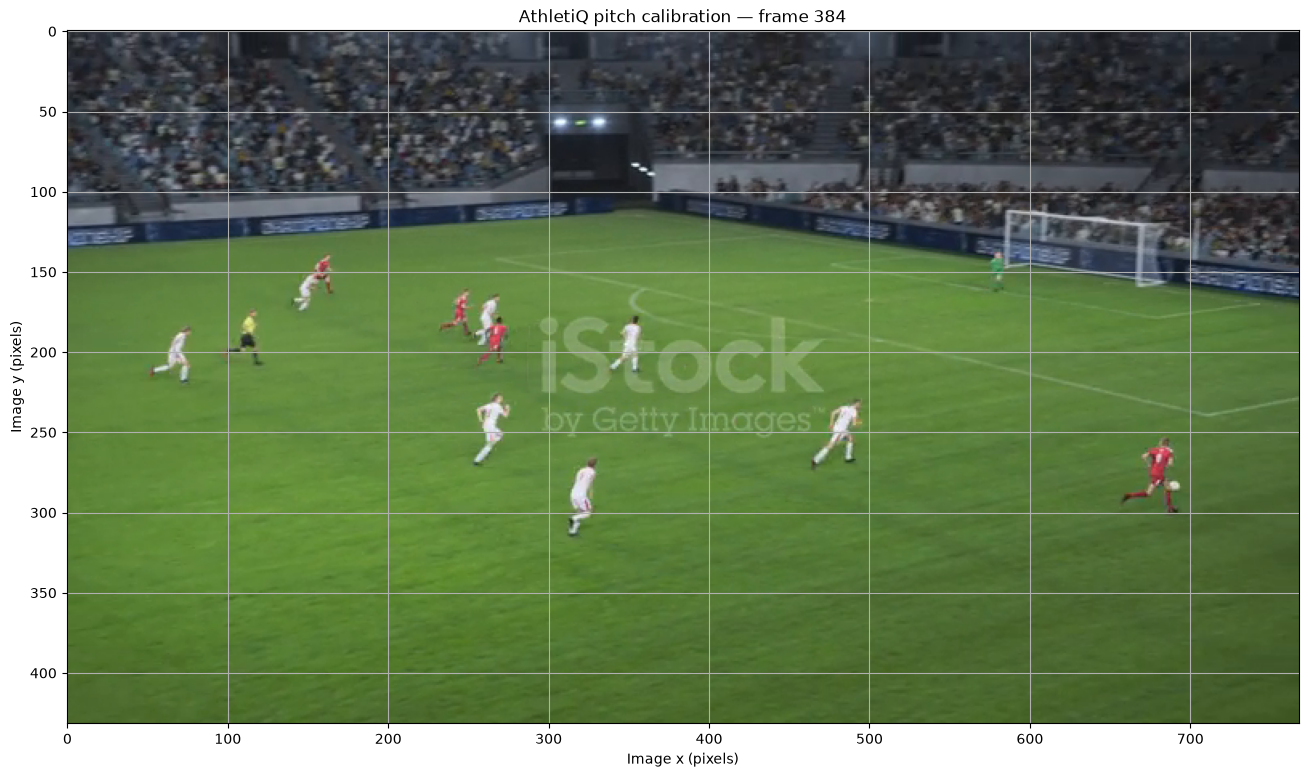

In [24]:

from pathlib import Path
import cv2
import matplotlib.pyplot as plt

video_path = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "datasets/football/raw/videos/football2.mp4"
)

cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, 384)
ok, frame = cap.read()
cap.release()

if not ok:
    raise RuntimeError("Could not read frame 384")

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 9))
plt.imshow(frame_rgb)
plt.title("AthletiQ pitch calibration — frame 384")
plt.xlabel("Image x (pixels)")
plt.ylabel("Image y (pixels)")
plt.grid()
plt.show()


In [25]:

from pathlib import Path
import json
import pandas as pd

root = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
cal = root / "outputs/calibration"

summary = cal / "pnlcalib/calibration_summary.csv"
if summary.exists():
    df = pd.read_csv(summary)
    print("PnLCalib summary shape:", df.shape)
    print(df.head(10).to_string(index=False))
else:
    print("PnLCalib summary not found:", summary)

for p in [
    cal / "association/calibration_association_audit.json",
    cal / "football2_circle_diagnostic.json",
    cal / "football2_calibration_frame0.json",
    cal / "football2_calibration_frame384.json",
]:
    print(f"\n--- {p.name} ---")
    if p.exists():
        try:
            print(json.dumps(json.loads(p.read_text()), indent=2)[:5000])
        except Exception as e:
            print("Could not parse JSON:", e)
    else:
        print("Not present")


PnLCalib summary shape: (15, 15)
 frame_id  time_seconds  calibration_returned mode  use_ransac  rep_err  pan_degrees  tilt_degrees  roll_degrees  x_focal_length  y_focal_length                status                                                                                         overlay_path                                                                                         parameters_path  error
        0           0.0                  True full           0 1.703178     0.222139     81.018265     -0.473907     1199.043591     1199.043591 candidate_unvalidated /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/pnlcalib/overlays/frame_000000_0000.00s.jpg /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/pnlcalib/parameters/frame_000000_0000.00s.json    NaN
       50           2.0                  True full           0 3.121371    -2.897990     81.758341     -0.686254     1091.092836     1091.092836 candidate_unvalidated /mnt/d/My Projects/AthletiQ/AthletiQ/outpu

Parameter file: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/pnlcalib/parameters/frame_000400_0016.00s.json
{
  "mode": "full",
  "use_ransac": 0,
  "rep_err": 1.211464031180683,
  "cam_params": {
    "pan_degrees": 38.27967833128201,
    "tilt_degrees": 78.9803287178367,
    "roll_degrees": 0.693324276403071,
    "x_focal_length": 1046.0293790901217,
    "y_focal_length": 1046.0293790901217,
    "principal_point": [
      383.5,
      215.5
    ],
    "position_meters": [
      -1.0436533537110577,
      49.13295318634763,
      -10.50752596801822
    ],
    "rotation_matrix": [
      [
        0.7835057908135471,
        0.6212709582354642,
        0.011877382490530941
      ],
      [
        -0.12790524710141501,
        0.1425416260240292,
        0.9814897516603787
      ],
      [
        0.6080780570992217,
        -0.7705220835924262,
        0.1911460048518458
      ]
    ],
    "radial_distortion": [
      0.0,
      0.0,
      0.0,
      0.0,
      0.0,
      0.

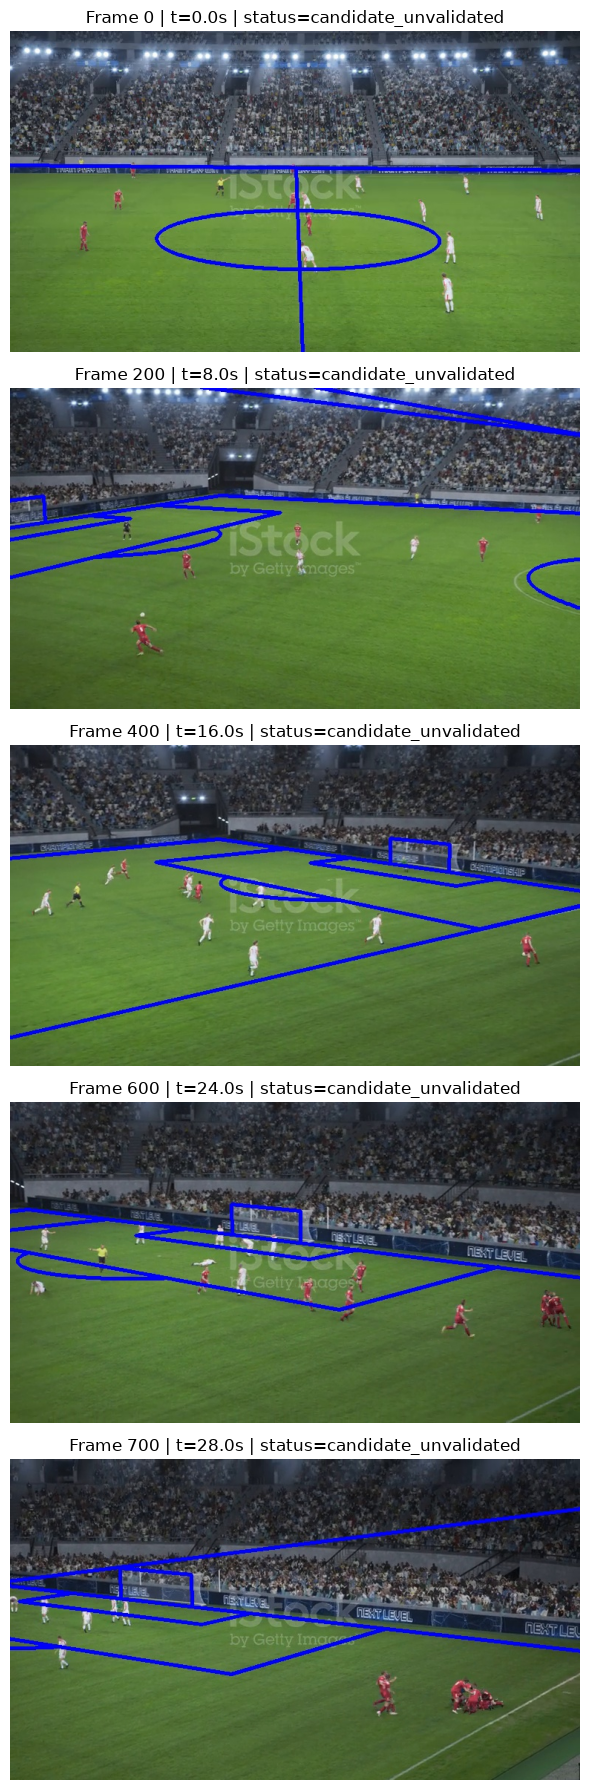

In [26]:

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

root = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
cal = root / "outputs/calibration/pnlcalib"

# Inspect the actual parameter format.
params = cal / "parameters/frame_000400_0016.00s.json"
if params.exists():
    data = json.loads(params.read_text())
    print("Parameter file:", params)
    print(json.dumps(data, indent=2)[:6000])
else:
    print("Parameter file not found:", params)

# Compare calibration overlays at different times.
summary = pd.read_csv(cal / "calibration_summary.csv")
samples = summary.iloc[[0, 4, 8, 12, 14]]

fig, axes = plt.subplots(len(samples), 1, figsize=(14, 18))
for ax, (_, row) in zip(axes, samples.iterrows()):
    path = Path(row["overlay_path"])
    if path.exists():
        ax.imshow(Image.open(path))
        ax.set_title(
            f"Frame {row['frame_id']} | "
            f"t={row['time_seconds']}s | "
            f"status={row['status']}"
        )
    else:
        ax.set_title(f"Missing overlay: {path}")
    ax.axis("off")

plt.tight_layout()
plt.show()
